TP4 - Jann Luna Pedro - Seaborn - 29/11/2025

L'activité proposée par TP4 consiste à visualiser les données afin de découvrir les principales fonctionnalités de Seaborn et ses améliorations par rapport à Matplotlib.

In [109]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [110]:
data = pd.read_csv("olympics.csv", sep="\t")
# data.head()

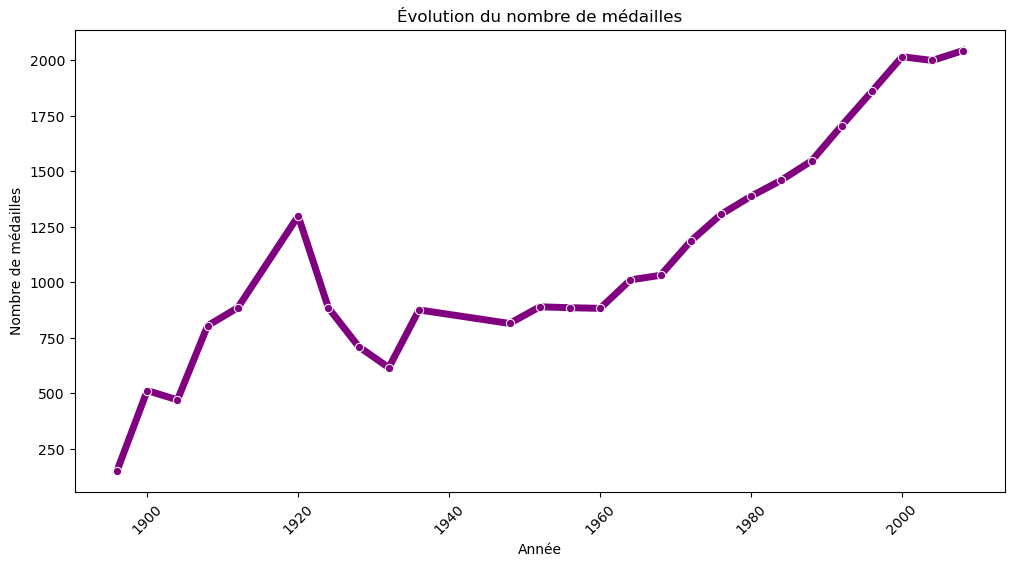

In [111]:
#1. analyser l'évolution du nombre total de médailles par année

#médailles par année
comptes_annee = data['Year'].value_counts()

#mettre en ordre chronologique 
comptes_tries = comptes_annee.sort_index()

plt.figure(figsize=(12, 6)) 
sns.lineplot(x=comptes_tries.index, y=comptes_tries.values, linewidth=5, color='purple', marker='o')
plt.title("Évolution du nombre de médailles")
plt.ylabel("Nombre de médailles")
plt.xlabel("Année")
plt.xticks(rotation=45)
plt.show()

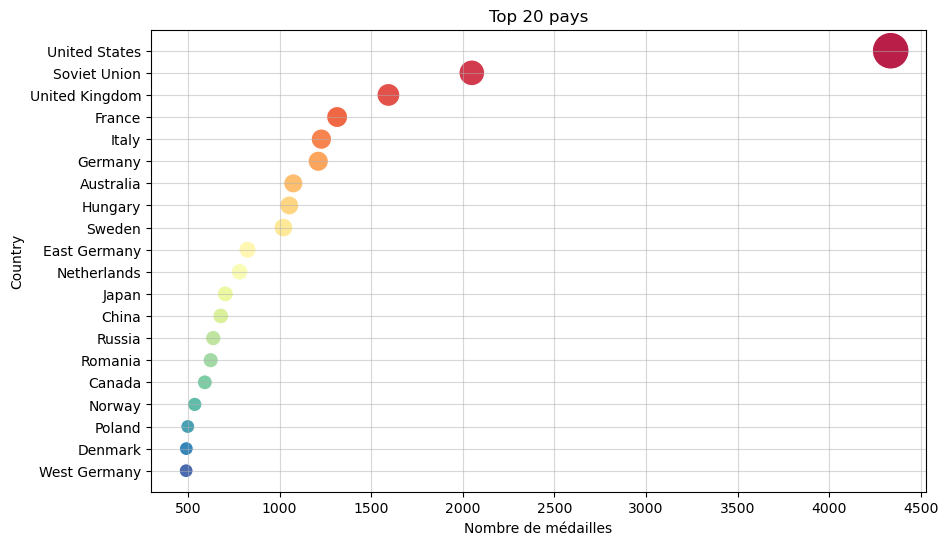

In [112]:
#2. analyser le classement des 20 pays avec plus de médailles

#médailles par pays
total_pays = data['Country'].value_counts()

#top 20
top10 = total_pays.head(20)

#Dot Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x=top10.values, y=top10.index,size=top10.values, hue=top10.index, sizes = (100,700), palette='Spectral', legend=False)
plt.title("Top 20 pays")
plt.xlabel("Nombre de médailles")
plt.grid(True, linestyle='-', alpha=0.5) # La grille aide à lire la valeur du point
plt.show()

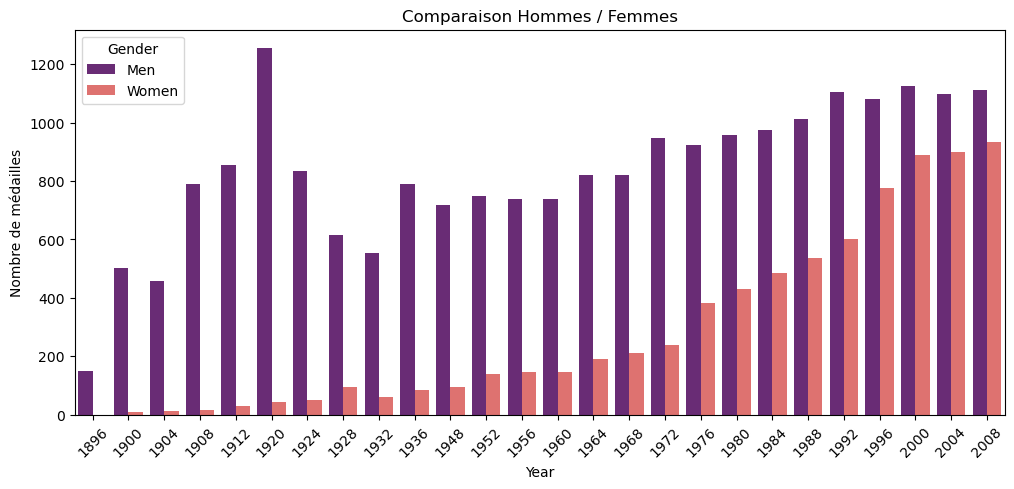

In [113]:
#3. comparer le nombre de médailles entre les hommes et les femmes au fil du temps

#grouper par année et genre
groupe_genre = data.groupby(['Year', 'Gender']).size()

#ajuster en forme de tableau
tableau_genre = groupe_genre.reset_index(name='Total')

plt.figure(figsize=(12, 5))
sns.barplot(x='Year', y='Total', hue='Gender', data=tableau_genre, palette='magma')
plt.title("Comparaison Hommes / Femmes")
plt.ylabel("Nombre de médailles")
plt.xticks(rotation=45)
plt.show()

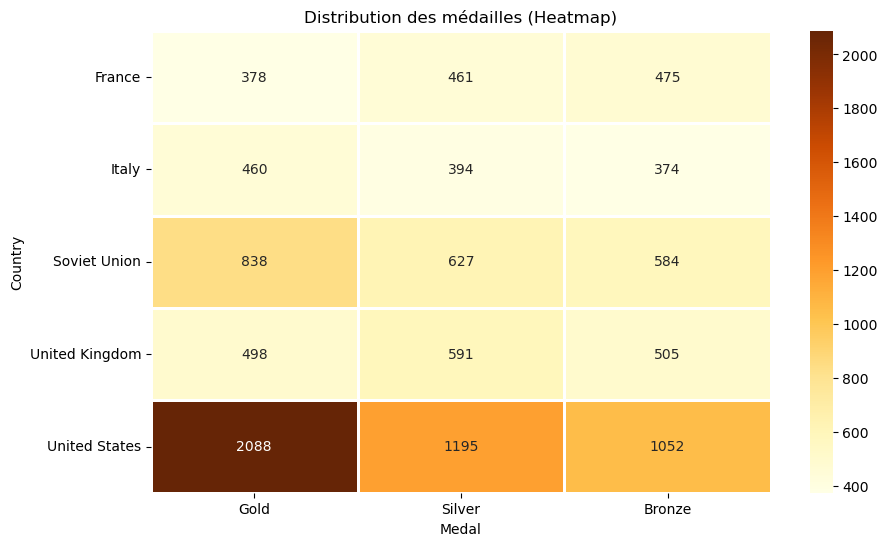

In [114]:
#4. analyser la répartition des médailles pour les top 5 pays.

# les top 5 meilleurs pays
top5_noms = data['Country'].value_counts().head(5).index
data_top5 = data[data['Country'].isin(top5_noms)]

#matrice (Pays en lignes, Médailles en colonnes)
matrice = pd.crosstab(data_top5['Country'], data_top5['Medal'])

#colonnes (Or, Argent, Bronze)
matrice = matrice[['Gold', 'Silver', 'Bronze']]

#carte de chaleur
plt.figure(figsize=(10, 6))
sns.heatmap(matrice, annot=True, fmt='d', cmap='YlOrBr', linewidths=1)
plt.title("Distribution des médailles (Heatmap)")
plt.show()

C:\Users\pedro\AppData\Local\Temp\ipykernel_5152\300317203.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_sports.index, y=top_sports.values, palette='plasma')


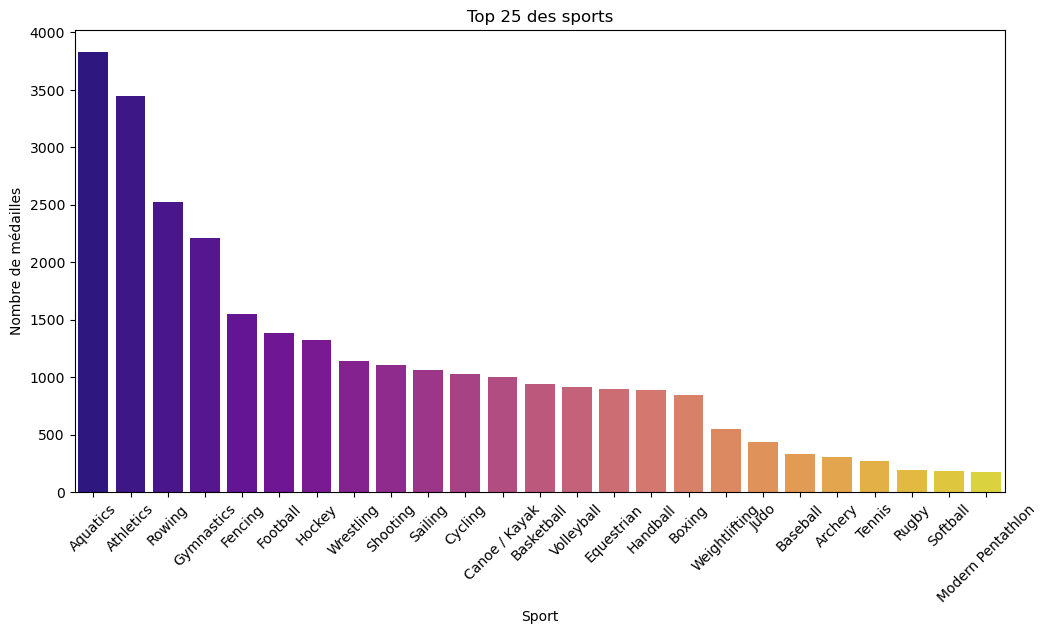

In [115]:
#5. analyser les sports qui ont distribué le plus de médailles

#sports
comptes_sports = data['Sport'].value_counts()

#25 premiers
top_sports = comptes_sports.head(25)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_sports.index, y=top_sports.values, palette='plasma')
plt.title("Top 25 des sports")
plt.ylabel("Nombre de médailles")
plt.xticks(rotation=45)
plt.show()

Je vais également faire une visualisation avec les ensembles de données internes de seaborn (iris).

C:\Users\pedro\AppData\Local\Temp\ipykernel_5152\880114599.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='species', y='petal_length', data=moyennes_final, palette='husl')


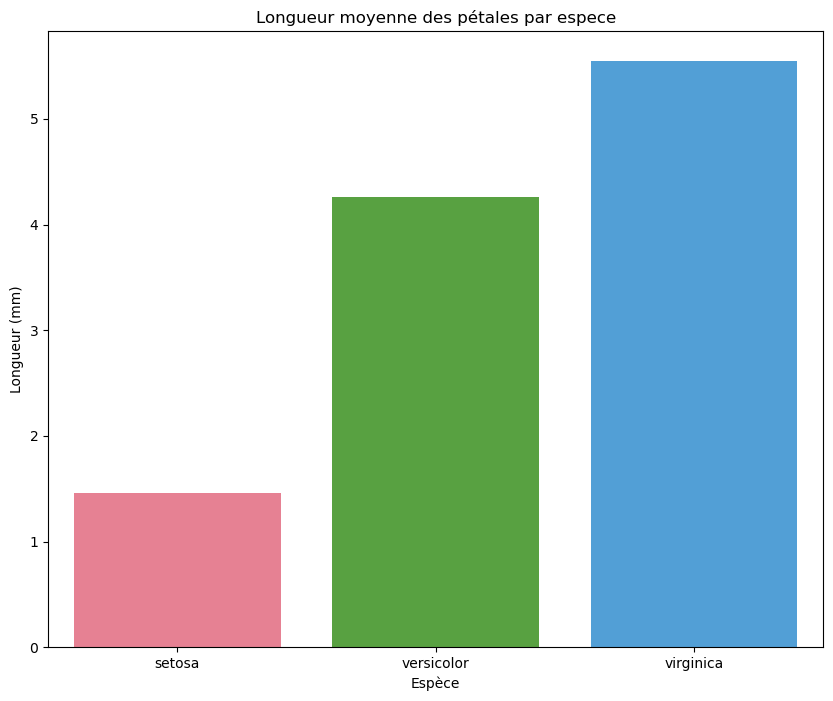

In [116]:
#6. calculer et comparer la longueur moyenne des pétales pour espece de fleur

iris = sns.load_dataset("iris")

#groupe = species
groupe_especes = iris.groupby('species')

#longueur des pétales, moyenne et ajuster
petales = groupe_especes['petal_length']
moyenne_par_espece = petales.mean()
moyennes_final = moyenne_par_espece.reset_index()

plt.figure(figsize=(10, 8))
sns.barplot(x='species', y='petal_length', data=moyennes_final, palette='husl')
plt.title("Longueur moyenne des pétales par espece")
plt.ylabel("Longueur (mm)")
plt.xlabel("Espèce")
plt.show()

Commentaires :

Il est remarquable de voir à quel point Seaborn améliore la visualisation et les palettes de couleurs sont très agréables à utiliser.

Je connaissais Seaborn principalement pour ses cartes thermiques, mais je ne savais pas qu'il avait autant d'autres fonctions.

Concernant le célèbre ensemble de données Iris, ma première idée était de visualiser le nombre de plantes par espèce dans la base de données, mais après avoir généré le graphique, je me suis rendu compte qu'il y avait 150 plantes réparties en 3 groupes de 50, ce qui n'était pas très intéressant à visualiser. Je suis donc passé à la taille moyenne des pétales des plantes.

